# LABORATORUL 2 - Rezolvari si Dezvoltari

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from pyod.utils.data import generate_data_clusters
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from scipy.io import loadmat
from pyod.utils.utility import standardizer
from pyod.models.combination import average, maximization
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from sklearn.metrics import balanced_accuracy_score

import warnings
warnings.filterwarnings('ignore')

### Exercitiul 1 - Scoruri Leverage

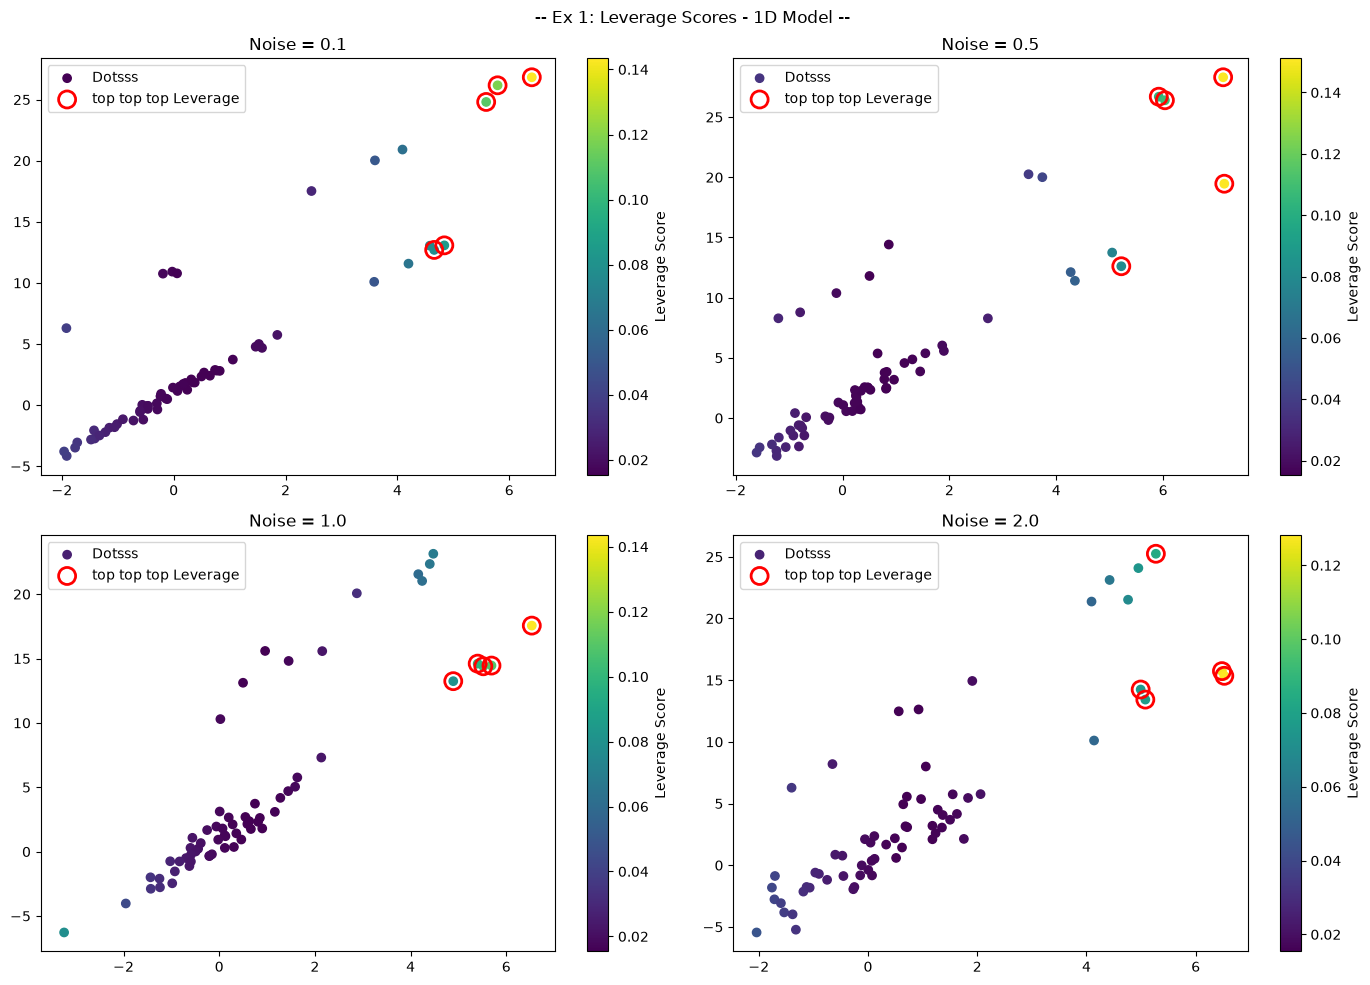

In [18]:
def compute_leverage(X):
    X_aug = np.c_[np.ones(X.shape[0]), X] # add coll of ones for bias
    H = X_aug @ np.linalg.pinv(X_aug.T @ X_aug) @ X_aug.T # calculate H matrix: H = X(X^T X)^-1 X^T
    return np.diag(H)

#params
np.random.seed(42)
a, b = 2.5, 1.0
n_points = 50
variances = [0.1, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("-- Ex 1: Leverage Scores - 1D Model -- ")

for ax, var in zip(axes.ravel(), variances):
    x_reg = np.random.normal(0, 1, n_points)
    y_reg = a * x_reg + b + np.random.normal(0, np.sqrt(var), n_points)
    
    x_hx = np.random.normal(5, 1, 5)
    y_hx = a * x_hx + b + np.random.normal(0, np.sqrt(var), 5)
    
    x_hy = np.random.normal(0, 1, 5)
    y_hy = a * x_hy + b + np.random.normal(10, np.sqrt(var), 5)
    
    x_hxy = np.random.normal(5, 1, 5)
    y_hxy = a * x_hxy + b + np.random.normal(10, np.sqrt(var), 5)
    
    X = np.concatenate([x_reg, x_hx, x_hy, x_hxy])
    Y = np.concatenate([y_reg, y_hx, y_hy, y_hxy])
    
    leverage = compute_leverage(X.reshape(-1, 1))
    
    top_indices = np.argsort(leverage)[-5:]
    
    scatter = ax.scatter(X, Y, c=leverage, cmap='viridis', label='Dotsss')
    ax.scatter(X[top_indices], Y[top_indices], edgecolor='red', facecolor='none', s=150, lw=2, label='top top top Leverage')
    ax.set_title(f"Noise = {var}")
    fig.colorbar(scatter, ax=ax, label='Leverage Score')
    ax.legend()

plt.tight_layout()
plt.show()


### Exercitiul 2 - Anomaly Detection dar cu KNN

Balanced Accuracy Train (k=5): 0.9878
Balanced Accuracy Test (k=5): 1.0000


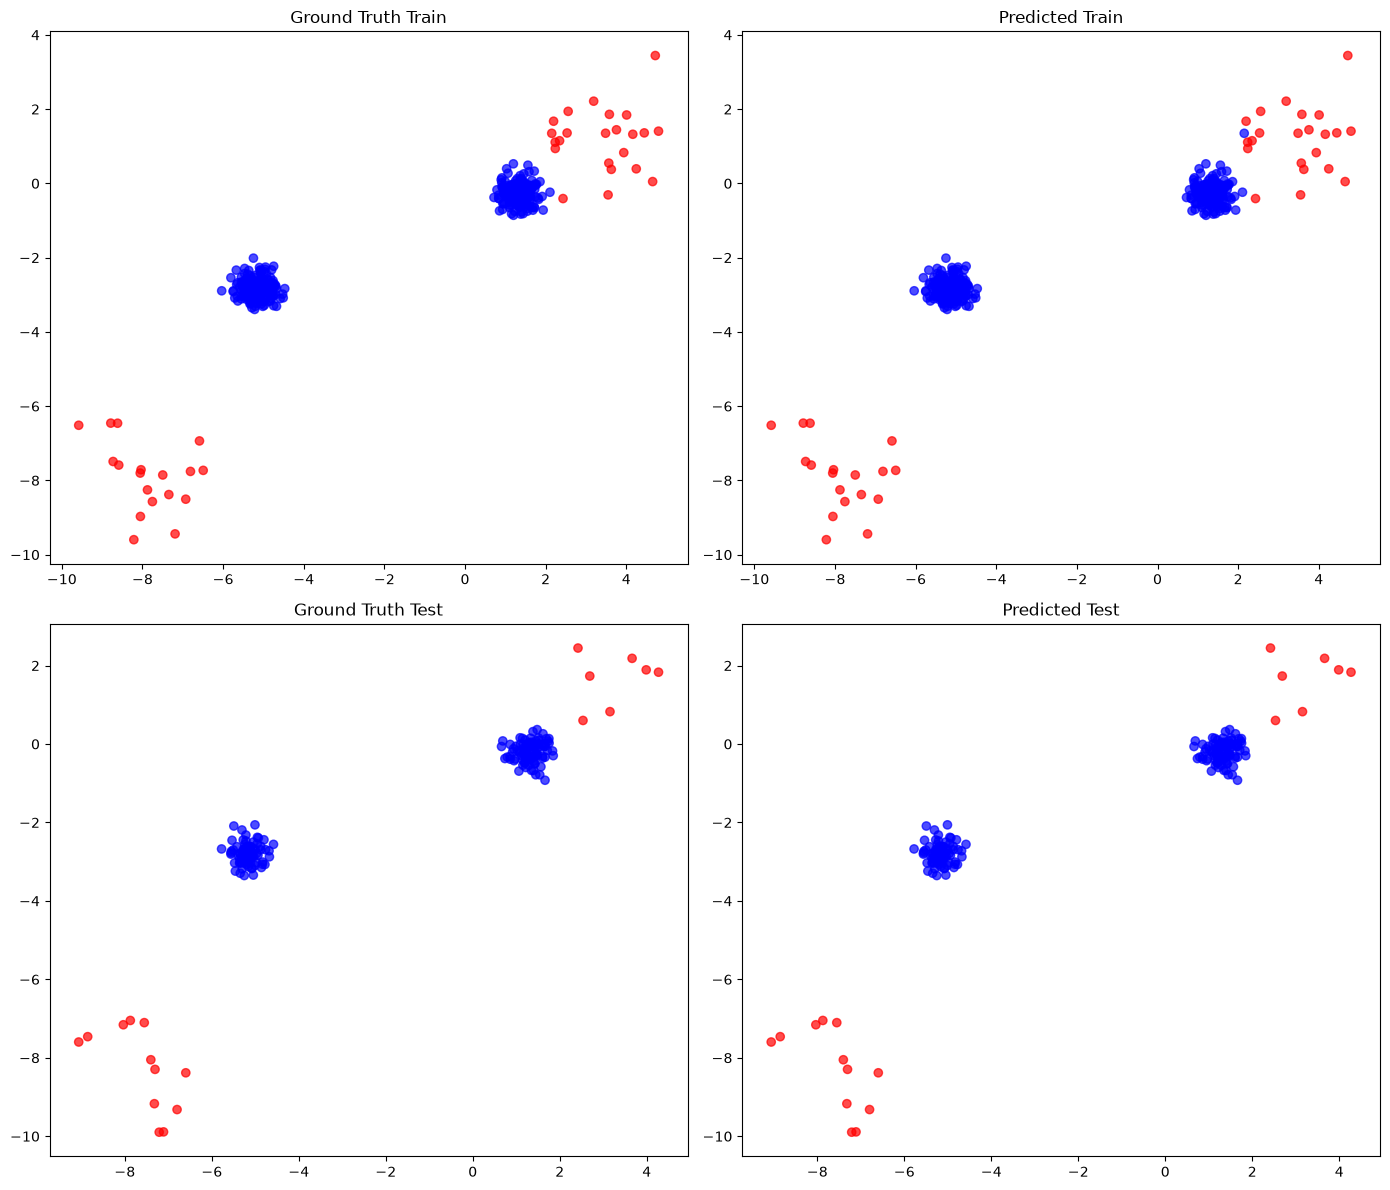

In [19]:
X_train, X_test, y_train, y_test = generate_data_clusters(
    n_train=400, n_test=200, n_clusters=2, n_features=2,
    contamination=0.1, size='same', density='same', dist=0.25, random_state=42
)

n_neighbors = 5 #  we can work with diff values like 2, 5, 20
knn = KNN(n_neighbors=n_neighbors)
knn.fit(X_train)

#predict 
y_train_pred = knn.labels_
y_test_pred = knn.predict(X_test)

#calculate the balanced accuracy 
ba_train = balanced_accuracy_score(y_train, y_train_pred)
ba_test = balanced_accuracy_score(y_test, y_test_pred)
print(f"Balanced Accuracy Train (k={n_neighbors}): {ba_train:.4f}")
print(f"Balanced Accuracy Test (k={n_neighbors}): {ba_test:.4f}")

#plot plot plot plot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr', alpha=0.7)
axes[0, 0].set_title("Ground Truth Train")

axes[0, 1].scatter(X_train[:, 0], X_train[:, 1], c=y_train_pred, cmap='bwr', alpha=0.7)
axes[0, 1].set_title("Predicted Train")

axes[1, 0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr', alpha=0.7)
axes[1, 0].set_title("Ground Truth Test")

axes[1, 1].scatter(X_test[:, 0], X_test[:, 1], c=y_test_pred, cmap='bwr', alpha=0.7)
axes[1, 1].set_title("Predicted Test")

plt.tight_layout()
plt.show()

### Exercitiul 3 - KNN Limitations - The L from Limitations can be changed with the L from LOF

#### Distance VS Density

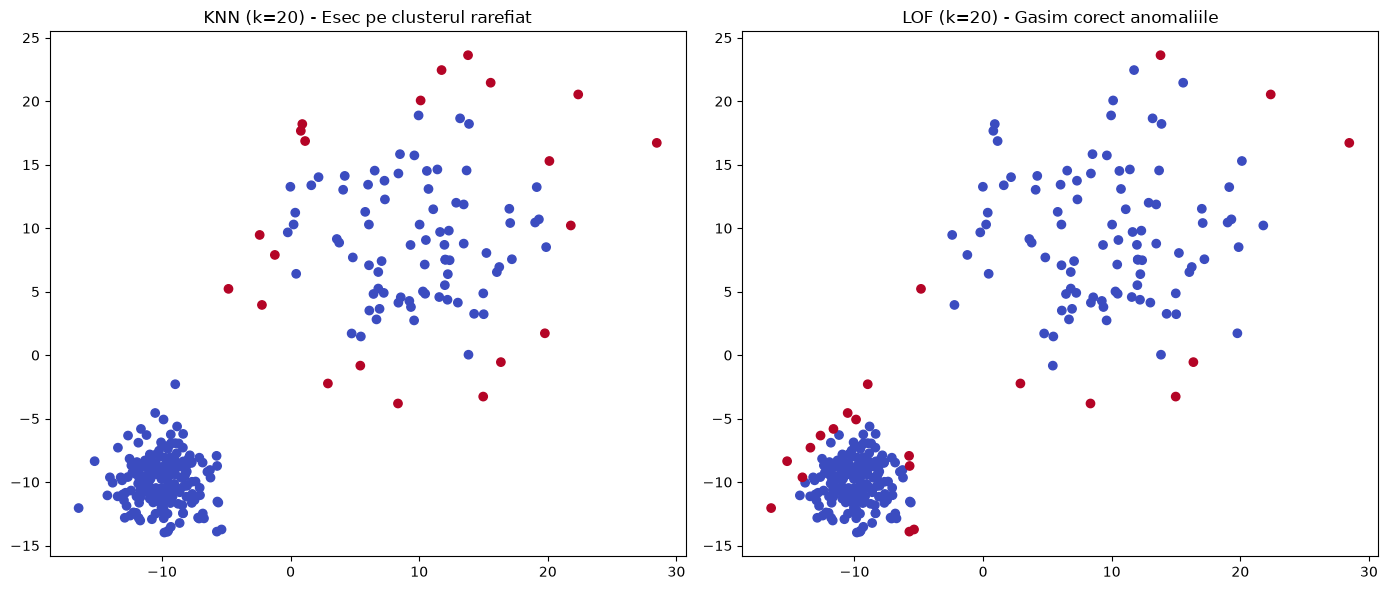

In [20]:
X_blobs, y_blobs = make_blobs(
    n_samples=[200, 100], n_features=2, 
    centers=[(-10, -10), (10, 10)],
    cluster_std=[2.0, 6.0],
    shuffle=True, random_state=42
)

contamination_rate = 0.07
n_neighbors = 20

knn_model = KNN(n_neighbors=n_neighbors, contamination=contamination_rate)
lof_model = LOF(n_neighbors=n_neighbors, contamination=contamination_rate)

knn_model.fit(X_blobs)
lof_model.fit(X_blobs)

y_pred_knn = knn_model.labels_
y_pred_lof = lof_model.labels_

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_pred_knn, cmap='coolwarm')
axes[0].set_title(f"KNN (k={n_neighbors}) - Esec pe clusterul rarefiat")

axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_pred_lof, cmap='coolwarm')
axes[1].set_title(f"LOF (k={n_neighbors}) - Gasim corect anomaliile")

plt.tight_layout()
plt.show()

### Exercitiul 4 - Cardio dataset

In [21]:
data_path = Path("Data") / "cardio.mat"
if not data_path.is_file():
    data_path = Path("Lab2") / data_path

data = loadmat(data_path)
X = data["X"]
y = data["y"].ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
X_train_scaled, X_test_scaled = standardizer(X_train, X_test)

neighbor_counts = range(30, 130, 10)
train_scores = np.empty((len(y_train), len(neighbor_counts)))
test_scores = np.empty((len(y_test), len(neighbor_counts)))

for column, n_neighbors in enumerate(neighbor_counts):
    model = KNN(n_neighbors=n_neighbors)
    model.fit(X_train_scaled)
    train_scores[:, column] = model.decision_scores_
    test_scores[:, column] = model.decision_function(X_test_scaled)

train_scores, test_scores = standardizer(train_scores, test_scores)
train_average = average(train_scores)
test_average = average(test_scores)
train_max = maximization(train_scores)
test_max = maximization(test_scores)

contamination = np.mean(y_train == 1)
average_threshold = np.quantile(train_average, 1 - contamination)
max_threshold = np.quantile(train_max, 1 - contamination)
average_predictions = (test_average > average_threshold).astype(int)
max_predictions = (test_max > max_threshold).astype(int)

print(f"Balanced accuracy (average): {balanced_accuracy_score(y_test, average_predictions):.4f}")
print(f"Balanced accuracy (maximum): {balanced_accuracy_score(y_test, max_predictions):.4f}")


Balanced accuracy (average): 0.7879
Balanced accuracy (maximum): 0.7816
